# 05 Logistic Hyper-parameter

## Logistic regression hyperparameters: meaning, uses, and selection

This notebook explains **what logistic regression hyperparameters control, why we use them, when to change them, and how to select them with scikit-learn**. It covers binary and multinomial logistic regression.

You will learn to control regularization, choose compatible solvers, diagnose convergence, address class imbalance, and tune a model without leaking validation data into preprocessing.

**Documentation:** The official [LogisticRegression API](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) and [GridSearchCV API](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) were consulted directly. Explanations and experiments are developed here. Additional official links appear at the end.

**How to run:** Choose a Python kernel with NumPy, pandas, Matplotlib, scikit-learn, and packaging installed, then Run All. If needed, install these packages in that environment using: pip install numpy pandas matplotlib scikit-learn packaging. All datasets are locally generated or bundled; no dataset download is required.

**Version awareness:** The stable documentation consulted identifies itself as scikit-learn **1.9.1**. Since 1.8, penalty is deprecated in favor of l1_ratio and C, with removal scheduled for 1.10. The helper below selects current or legacy syntax. It targets scikit-learn **1.2 and later**; the version printed below identifies the environment used for saved outputs.

In [1]:
import sys
import warnings
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from packaging.version import Version
from IPython.display import display
from sklearn.datasets import make_classification, load_iris
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
    classification_report, ConfusionMatrixDisplay, f1_score, log_loss,
    precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (train_test_split, StratifiedKFold,
    GridSearchCV, cross_validate, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

assert Version(sklearn.__version__) >= Version("1.2")
NEW_API = Version(sklearn.__version__) >= Version("1.8")
print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("Syntax:", "l1_ratio + C" if NEW_API else "penalty + l1_ratio")
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True})

Python: 3.14.3
scikit-learn: 1.9.1
Syntax: l1_ratio + C


## 1. Parameters versus hyperparameters

A **parameter** is learned from training data. Logistic regression estimates coefficients and an intercept:

$$p(y=1\mid\mathbf{x})=\sigma(\mathbf{w}^\top\mathbf{x}+b),
\qquad \sigma(z)=\frac{1}{1+e^{-z}}.$$

A **hyperparameter** configures the model or training process before a fit. For example, C=0.1 specifies regularization strength, and solver='lbfgs' selects the optimizer. Cross-validation can select these settings, but the optimizer learns the coefficients for each candidate.

| Category | Examples | Role |
|---|---|---|
| Learned parameters | coef_, intercept_ | Fitted score function |
| Modeling hyperparameters | C, l1_ratio, class_weight, fit_intercept | Objective or model family |
| Optimization settings | solver, tol, max_iter, dual | How the objective is solved |
| Operational settings | random_state, warm_start, verbose | Repeatability, initialization, logging |

Trailing underscores usually mark fitted attributes. **n_iter_** is the observed iteration count; **max_iter** is the configured limit.

**Why use hyperparameters?** To control overfitting, choose coefficient sparsity, account for class costs, and solve the objective efficiently. Not every setting needs a search: random seeds should be fixed for repeatability, and iteration budgets should ensure convergence.

In [2]:
defaults = LogisticRegression().get_params()
display(pd.DataFrame({"setting": list(defaults),
                      "installed_default": list(defaults.values())}))

,setting,installed_default
0,C,1.0
1,class_weight,None
2,dual,False
3,fit_intercept,True
4,intercept_scaling,1
5,l1_ratio,0.0
6,max_iter,100
7,n_jobs,None
8,penalty,deprecated
9,random_state,None


## 2. Regularization and C

Binary cross-entropy for example i is

$$L_i=-y_i\log p_i-(1-y_i)\log(1-p_i).$$

Unpenalized fitting focuses entirely on training labels. Large coefficients can fit noise or produce unstable estimates. On separable data, a finite unregularized maximum likelihood estimate may not exist. **Regularization adds a cost for large coefficients**, trading training fit for stability and simplicity. Validate its strength; improvement is not guaranteed.

The [scikit-learn user guide](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression) writes the weighted objective in the form

$$J(\mathbf{w},b)=\frac1S\sum_i s_iL_i+\frac{r(\mathbf{w})}{SC},
\qquad S=\sum_i s_i,$$

where s_i combines class and sample weights. For unit weights S=n. The multinomial data loss replaces binary cross-entropy with $-\sum_k t_{ik}\log p_{ik}$.

For L2, $r(\mathbf{w})=\tfrac12\|\mathbf{w}\|_2^2$. If another formula uses average loss plus $\tfrac\lambda2\|\mathbf{w}\|_2^2$, then $\lambda=1/(SC)$ under this scaling. Identifying C with 1/lambda without checking normalization is misleading.

### C — inverse regularization strength

**Default: 1.0.** Use positive finite values for regularized fits.

| C | Relative regularization | Typical effect |
|---:|---|---|
| 0.001 | Strong | Smaller coefficients; may underfit |
| 0.1 | Weaker than 0.001 | More signal can enter |
| 1 | Default baseline | Useful starting point, not universal optimum |
| 100 | Weak relative to 1 | Larger coefficients; may fit noise |

**Why change it?** Stronger shrinkage can help with noisy or numerous features; weaker shrinkage can recover useful signal that a strong penalty suppresses.

**How to choose it?** Search logarithmically: 0.001, 0.01, 0.1, 1, 10, 100. Select using validation scores, not training accuracy. Larger C does not always improve validation performance.

C is **not** a learning rate, decision threshold, or softmax temperature. Current unpenalized syntax is C=np.inf; before 1.8 use penalty=None. Most solvers leave the intercept unpenalized; liblinear is an exception discussed below.

## 3. L1, L2, Elastic-Net, and l1_ratio

Let rho denote l1_ratio. Elastic-Net uses

$$r(\mathbf{w})=\rho\|\mathbf{w}\|_1+
\frac{1-\rho}{2}\|\mathbf{w}\|_2^2,\qquad 0\leq\rho\leq1.$$

| Penalty | Formula | Why use it? | Tradeoff |
|---|---|---|---|
| L2 | $\tfrac12\sum_jw_j^2$ | Smooth coefficient shrinkage; useful with correlated/noisy features | Usually keeps coefficients nonzero |
| L1 | $\sum_j|w_j|$ | Can produce exact zeros; useful for sparse models | Selection among correlated features can be unstable |
| Elastic-Net | Mixture above | Sparsity plus L2 shrinkage | Adds a mixture setting to select |
| None | 0 | Unpenalized likelihood estimation | Can be unstable or non-finite |

**C controls overall strength; l1_ratio controls the mixture.** Increasing l1_ratio is not simply increasing total regularization.

| Intent | scikit-learn 1.8+ | Before 1.8 |
|---|---|---|
| L2 | l1_ratio=0 | penalty='l2' |
| L1 | l1_ratio=1 | penalty='l1' |
| Elastic-Net | l1_ratio=0.5 | penalty='elasticnet', l1_ratio=0.5 |
| No penalty | C=np.inf | penalty=None |

Before 1.8, l1_ratio is used only with Elastic-Net. In current versions it specifies penalty type directly. The helper below handles both APIs without globally suppressing deprecation warnings.

**Feature scaling matters:** A penalty operates on coefficient magnitudes. Changing feature units changes those magnitudes. Put scaling inside a Pipeline so each validation fold learns preprocessing from its training portion only.

In [3]:
def make_logistic(C=1.0, ratio=0.0, solver="lbfgs", **kwargs):
    settings = dict(C=C, solver=solver, max_iter=2000, tol=1e-4)
    if NEW_API:
        settings["l1_ratio"] = ratio
    elif np.isinf(C):
        settings.update(C=1.0, penalty=None)
    elif ratio == 0:
        settings["penalty"] = "l2"
    elif ratio == 1:
        settings["penalty"] = "l1"
    else:
        settings.update(penalty="elasticnet", l1_ratio=ratio)
    settings.update(kwargs)
    return LogisticRegression(**settings)


def make_pipeline_model(**kwargs):
    return Pipeline([("scale", StandardScaler()),
                     ("logistic", make_logistic(**kwargs))])


print("L2:", make_logistic(ratio=0))
print("L1:", make_logistic(ratio=1, solver="saga"))
print("Elastic-Net:", make_logistic(ratio=0.5, solver="saga"))

L2: LogisticRegression(l1_ratio=0, max_iter=2000)
L1: LogisticRegression(l1_ratio=1, max_iter=2000, solver='saga')
Elastic-Net: LogisticRegression(l1_ratio=0.5, max_iter=2000, solver='saga')


## 4. solver — choose the optimization algorithm

**Default: lbfgs.** A solver is the numerical algorithm used to fit the objective. Compatible solvers converged to the same objective generally differ primarily in computational cost, rather than intentionally changing complexity. Nonunique solutions and finite tolerances can produce differences.

| Solver | Regularization | Joint multinomial? | When useful |
|---|---|---|---|
| lbfgs | L2 or none | Yes | Good general baseline; limited-memory quasi-Newton |
| liblinear | L1 or L2 | No | Small binary problems; L2 dual option |
| newton-cg | L2 or none | Yes | Newton steps using conjugate gradients |
| newton-cholesky | L2 or none | Yes from 1.6 | Samples greatly exceed features × classes; adequate memory |
| sag | L2 or none | Yes | Large datasets, similarly scaled features |
| saga | L1, L2, Elastic-Net, or none | Yes | Sparse penalties or large scaled datasets |

newton-cholesky forms a full Hessian, with memory growing quadratically in features × classes. sag and saga particularly benefit from scaling.

**Invalid combinations:** L1 with lbfgs, Elastic-Net with liblinear, or direct multinomial fitting with liblinear. liblinear also does not support unpenalized fits. For multiclass liblinear, use an explicit OneVsRestClassifier wrapper, which trains a different objective from joint multinomial regression.

## 5. max_iter and tol — convergence settings

### max_iter

**Default: 100.** Maximum optimizer iterations. This is not a guaranteed number of training passes, and solvers count iterations differently.

**Why increase it?** A fit that hits the limit may not have converged. Check scaling and solver compatibility, then raise the budget if needed. Increasing the budget after convergence does not force further fitting or necessarily cause overfitting.

### tol

**Default: 1e-4.** Tolerance for the stopping criterion. Smaller values request greater numerical accuracy and may take longer; larger values can stop earlier. The exact criterion is solver-specific, so it is not universally a threshold on changes in loss.

**Why change it?** Balance optimization accuracy and runtime. Treat tol and max_iter primarily as optimization controls, not as replacements for regularization.

**Diagnose:** Inspect ConvergenceWarning and the fitted n_iter_. The experiment later intentionally captures a one-iteration warning and reports it; warnings are not globally hidden.

## 6. class_weight — control each class's loss contribution

**Default: None**, equal class weights. Other choices are 'balanced' or a dictionary such as {0: 1, 1: 4}.

Without sample weights, balanced mode uses

$$\alpha_k=\frac{n}{K n_k},$$

where n_k is the training count of class k. With 900 negatives and 100 positives, weights are approximately 0.556 and 5.0. Thus each class contributes comparable total weight before considering its prediction errors.

**Why use it?** Reduce majority-class dominance or encode different error costs. A higher positive-class weight often improves its recall while increasing false positives and reducing precision. Balanced mode is a candidate to evaluate, not an automatic improvement.

If sample_weight is supplied to fit, it combines multiplicatively with class weights. sample_weight is a **fit argument**, not a constructor hyperparameter; it describes individual examples rather than whole classes.

Weighted training changes the probability-estimation target. Probabilities may need calibration or adjustment when estimating the original class distribution. Choose validation metrics that match the task: accuracy alone can hide poor minority recall.

## 7. fit_intercept and intercept_scaling

### fit_intercept

**Default: True.** Learn b in $z=\mathbf{w}^\top\mathbf{x}+b$. The intercept shifts the boundary and represents a baseline class tendency.

With False, binary logistic regression is constrained to $\mathbf{w}^\top\mathbf{x}=0$ at the boundary and predicts probability 0.5 at the feature origin. Use this constraint only when justified. Centering features does not automatically make an intercept unnecessary; the labels may remain imbalanced.

### intercept_scaling

**Default: 1.** Relevant only with **liblinear and fit_intercept=True**. The solver adds a constant synthetic feature s; if its coefficient is u, then b=su. That coefficient is penalized.

For a fixed intercept b, the synthetic coefficient's L2 penalty is $\tfrac12(b/s)^2$ and L1 penalty is $|b/s|$. Increasing s weakens the effective penalty on the intercept. It does not scale the other features, and it has no effect with lbfgs or other solvers.

## 8. Other settings and API changes

| Setting | Default | Meaning and use |
|---|---|---|
| dual | False | Primal versus dual formulation. True supports only L2 + liblinear; may help with features ≫ samples. Prefer False when samples exceed features. Benchmark. |
| random_state | None | Used by sag, saga, liblinear. Fix an integer for reproducibility; no effect on other solvers. Do not tune seeds for favorable scores. |
| warm_start | False | Reuse a previous fit's coefficients as initialization. Can help manual nearby fits; no benefit with liblinear. Not incremental learning. |
| verbose | 0 | Optimization logging, documented for lbfgs/liblinear. Useful for diagnosis, not predictive quality. |
| n_jobs | None | Current LogisticRegression: no effect, deprecated since 1.8. Omit it. GridSearchCV has a separate n_jobs that does parallelize search fits. |

**Multiclass history:** multi_class was deprecated in 1.5 and removed in 1.8. Current multiclass LogisticRegression uses joint multinomial loss with supported solvers. This notebook does not pass the removed argument.

**Warm-start detail:** GridSearchCV clones estimators for candidates/folds, so independent fits do not reuse each other's coefficients even if warm_start=True. For online learning, consider SGDClassifier(loss='log_loss'); its settings and multiclass implementation differ from LogisticRegression.

**Learning rate and temperature:** LogisticRegression exposes no constructor learning_rate or temperature argument. Its solvers manage optimization internally. Temperature is a separate probability-scaling/calibration operation, explained in the [README](README.md).

## 9. Experiments: reserve a test set first

Generate an imbalanced dataset with informative, redundant, and noisy features. All exploratory experiments and hyperparameter selection use only the development partition. The reserved test partition is evaluated after selection.

StandardScaler stays inside every Pipeline. During cross-validation each fold fits its scaler on its own training examples; fitting one scaler before CV leaks validation-fold statistics. StratifiedKFold preserves class proportions approximately. Grouped and temporal data need appropriate splitters rather than random independent-example splitting.

In [4]:
X, y = make_classification(n_samples=700, n_features=20,
    n_informative=6, n_redundant=4, weights=[0.85, 0.15],
    class_sep=1.0, flip_y=0.03, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("Development samples:", len(y_train))
print("Reserved test samples:", len(y_test))
counts = np.bincount(y_train)
display(pd.DataFrame({"class": np.arange(len(counts)),
    "training_count": counts,
    "balanced_weight": len(y_train)/(len(counts)*counts)}))

Development samples: 525
Reserved test samples: 175


,class,training_count,balanced_weight
0,0,445,0.589888
1,1,80,3.281250


### A. Effect of C on coefficients and validation performance

Coefficient norms are measured in standardized feature units. A larger norm does not mean a better model. The validation plot reports balanced accuracy (mean class recall). Its shaded band is one fold standard deviation, not a confidence interval. Poor training and validation scores can suggest underfitting; a large gap can suggest overfitting, but neither pattern is guaranteed solely by C.

,C,coefficient_L2_norm,training_balanced_accuracy,CV_balanced_accuracy
0,0.001,0.098723,0.500000,0.500000
1,0.010,0.574305,0.507812,0.506250
2,0.100,1.477976,0.647542,0.638764
3,1.000,2.044197,0.715081,0.667275
4,10.000,2.155613,0.716362,0.679775
5,100.000,2.168049,0.716362,0.679775


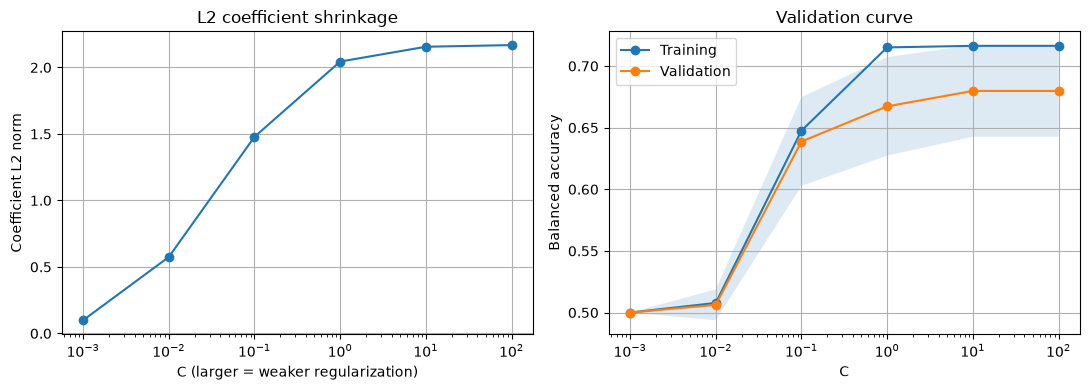

In [5]:
C_values = np.logspace(-3, 2, 6)
norms = []
for C in C_values:
    fitted = make_pipeline_model(C=C).fit(X_train, y_train)
    norms.append(np.linalg.norm(fitted.named_steps["logistic"].coef_))
train_scores, val_scores = validation_curve(
    make_pipeline_model(), X_train, y_train,
    param_name="logistic__C", param_range=C_values,
    scoring="balanced_accuracy", cv=cv, n_jobs=1)
display(pd.DataFrame({"C": C_values, "coefficient_L2_norm": norms,
    "training_balanced_accuracy": train_scores.mean(axis=1),
    "CV_balanced_accuracy": val_scores.mean(axis=1)}))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].semilogx(C_values, norms, marker="o")
axes[0].set(xlabel="C (larger = weaker regularization)",
    ylabel="Coefficient L2 norm", title="L2 coefficient shrinkage")
axes[1].semilogx(C_values, train_scores.mean(axis=1), marker="o", label="Training")
axes[1].semilogx(C_values, val_scores.mean(axis=1), marker="o", label="Validation")
axes[1].fill_between(C_values,
    val_scores.mean(axis=1)-val_scores.std(axis=1),
    val_scores.mean(axis=1)+val_scores.std(axis=1), alpha=0.15)
axes[1].set(xlabel="C", ylabel="Balanced accuracy", title="Validation curve")
axes[1].legend()
fig.tight_layout()
plt.show()

### B. Compare penalty sparsity

Use the same data, C, and SAGA solver for all penalties. Count approximately zero coefficients using a numerical threshold. A zero coefficient does not prove a feature has no relationship with the target, especially with correlated features. Counts depend on the selected C; L1 is not guaranteed to produce zeros at weak regularization.

In [6]:
sparsity_rows = []
for name, ratio in [("L2", 0.0), ("Elastic-Net", 0.5), ("L1", 1.0)]:
    fitted = make_pipeline_model(C=0.1, ratio=ratio, solver="saga",
                                random_state=42).fit(X_train, y_train)
    coef = fitted.named_steps["logistic"].coef_.ravel()
    sparsity_rows.append({"penalty": name, "l1_ratio": ratio,
        "approximately_zero": int(np.sum(np.abs(coef)<1e-6)),
        "total_coefficients": len(coef), "L2_norm": np.linalg.norm(coef)})
display(pd.DataFrame(sparsity_rows))

,penalty,l1_ratio,approximately_zero,total_coefficients,L2_norm
0,L2,0.0,0,20,1.477747
1,Elastic-Net,0.5,9,20,1.371743
2,L1,1.0,14,20,1.273115


### C. Class weights and the precision–recall tradeoff

Compare None and balanced mode using development-only CV. Class 1 is the minority. Precision, recall, and F1 refer to that positive class; balanced accuracy averages both class recalls. ROC AUC assesses ranking rather than one threshold.

Class weighting changes training. Threshold adjustment changes how fitted probabilities become labels. They are separate operations; choose thresholds on validation data, not on the final test set.

In [7]:
weight_rows = []
metrics = {"precision": "precision", "recall": "recall", "f1": "f1",
           "balanced_accuracy": "balanced_accuracy", "roc_auc": "roc_auc"}
for weight in [None, "balanced"]:
    scores = cross_validate(make_pipeline_model(C=1, class_weight=weight),
        X_train, y_train, cv=cv, scoring=metrics, n_jobs=1)
    weight_rows.append({"class_weight": str(weight), **{
        name: scores["test_"+name].mean() for name in metrics}})
display(pd.DataFrame(weight_rows))

,class_weight,precision,recall,f1,balanced_accuracy,roc_auc
0,None,0.624495,0.3750,0.465704,0.667275,0.847331
1,balanced,0.396785,0.7375,0.515019,0.768750,0.856320


### D. Diagnose convergence

Compare one iteration against an adequate budget on scaled development data. Warnings are captured locally and reported. Timing is machine-dependent; this is a demonstration rather than a benchmark or selection method.

In [8]:
convergence_rows = []
for budget in [1, 2000]:
    model = make_pipeline_model(max_iter=budget)
    start = perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X_train, y_train)
    warned = any(issubclass(w.category, ConvergenceWarning) for w in caught)
    convergence_rows.append({"max_iter": budget,
        "actual_iterations": int(model.named_steps["logistic"].n_iter_.max()),
        "convergence_warning": warned,
        "training_log_loss": log_loss(y_train, model.predict_proba(X_train)),
        "seconds": perf_counter()-start})
display(pd.DataFrame(convergence_rows))

,max_iter,actual_iterations,convergence_warning,training_log_loss,seconds
0,1,1,True,0.420050,0.002483
1,2000,9,False,0.272604,0.001771


## 10. Select hyperparameters using GridSearchCV

For each configuration h, fit on all but one fold and score on the held-out fold:

$$\operatorname{CV}(h)=\frac1F\sum_{f=1}^F
\operatorname{score}(\hat\theta_h^{(-f)},D_f).$$

Select the configuration with the largest mean validation score. A negative loss scorer is maximized by minimizing the positive loss.

We search C, penalty mixture, and class weights. A **list of dictionaries** separates compatible solver/penalty combinations. The prefix logistic__ addresses parameters of the Pipeline's logistic step.

| Search setting | Why use it? |
|---|---|
| param_grid | Specify candidate settings |
| cv | Define validation folds |
| scoring | Define evaluation metrics; separate from classifier hyperparameters |
| refit='balanced_accuracy' | Select by this metric, then refit on all development data |
| n_jobs=1 | Run serially in this small notebook; -1 can use all processors |
| error_score='raise' | Expose invalid configurations immediately |
| return_train_score=True | Compare training and validation scores |

Balanced accuracy is chosen because the example is imbalanced. If probability quality is the goal, choose neg_log_loss instead. The selected CV score is not an unbiased final performance estimate: it helped select settings. Use the reserved test set for separate evaluation, or nested CV to assess the whole tuning procedure.

In [9]:
common = {"logistic__C": [0.01, 0.1, 1.0, 10.0],
          "logistic__class_weight": [None, "balanced"]}
if NEW_API:
    param_grid = [
        {**common, "logistic__solver": ["lbfgs"], "logistic__l1_ratio": [0.0]},
        {**common, "logistic__solver": ["saga"], "logistic__l1_ratio": [0.5, 1.0]},
    ]
else:
    param_grid = [
        {**common, "logistic__solver": ["lbfgs"], "logistic__penalty": ["l2"]},
        {**common, "logistic__solver": ["saga"], "logistic__penalty": ["l1"]},
        {**common, "logistic__solver": ["saga"],
         "logistic__penalty": ["elasticnet"], "logistic__l1_ratio": [0.5]},
    ]
search = GridSearchCV(make_pipeline_model(random_state=42),
    param_grid=param_grid, cv=cv,
    scoring={"balanced_accuracy": "balanced_accuracy", "roc_auc": "roc_auc",
             "neg_log_loss": "neg_log_loss"},
    refit="balanced_accuracy", n_jobs=1, error_score="raise",
    return_train_score=True)
search.fit(X_train, y_train)
print("Candidates:", len(search.cv_results_["params"]))
print("CV folds:", search.n_splits_)
print("Best settings:", search.best_params_)
print("Best mean CV balanced accuracy:", round(search.best_score_, 4))
results = pd.DataFrame(search.cv_results_).sort_values("rank_test_balanced_accuracy")
display(results[["params", "mean_train_balanced_accuracy",
    "mean_test_balanced_accuracy", "std_test_balanced_accuracy",
    "mean_test_roc_auc", "mean_test_neg_log_loss"]].head(8))

Candidates: 24
CV folds: 5
Best settings: {'logistic__C': 0.1, 'logistic__class_weight': 'balanced', 'logistic__l1_ratio': 0.0, 'logistic__solver': 'lbfgs'}
Best mean CV balanced accuracy: 0.7761


,params,mean_train_balanced_accuracy,mean_test_balanced_accuracy,std_test_balanced_accuracy,mean_test_roc_auc,mean_test_neg_log_loss
3,"{'logistic__C': 0.1, 'logistic__class_weight':...",0.821559,0.776124,0.049025,0.858146,-0.462794
15,"{'logistic__C': 0.1, 'logistic__class_weight':...",0.809867,0.775632,0.059156,0.864466,-0.464745
1,"{'logistic__C': 0.01, 'logistic__class_weight'...",0.815133,0.770014,0.035949,0.861096,-0.517648
19,"{'logistic__C': 1.0, 'logistic__class_weight':...",0.824772,0.769874,0.050175,0.858287,-0.474141
5,"{'logistic__C': 1.0, 'logistic__class_weight':...",0.826615,0.768750,0.048845,0.856320,-0.476402
18,"{'logistic__C': 1.0, 'logistic__class_weight':...",0.824210,0.768750,0.048845,0.858006,-0.475018
14,"{'logistic__C': 0.1, 'logistic__class_weight':...",0.818715,0.766503,0.052168,0.863483,-0.461215
23,"{'logistic__C': 10.0, 'logistic__class_weight'...",0.826457,0.763624,0.053307,0.856180,-0.481529


### Interpret the results

best_params_ records the selected settings; best_estimator_ is the refitted Pipeline. Inside cv_results_, mean_test_* means **validation folds**, not the reserved final test set. Negative log loss closer to zero is better.

Small differences can be noise. Fold standard deviations are not formal confidence intervals. Prefer appropriate simple settings when differences are practically negligible.

**Alternatives:** RandomizedSearchCV samples a fixed number of configurations and can use log-uniform C distributions. LogisticRegressionCV provides built-in regularization CV. With learned preprocessing, GridSearchCV around the full Pipeline makes fold-specific preprocessing explicit. A scaler fitted outside an internal CV stage leaks its statistics into that stage's validation folds.

## 11. Final test evaluation

The main settings have been selected on development data. Evaluate the chosen model on the reserved test set. Do not use these results to keep changing settings while treating the same test set as untouched.

These results apply to this synthetic dataset and split; they are not a guarantee for other tasks. Probability columns follow the fitted classes_ order.

,accuracy,balanced_accuracy,minority_precision,minority_recall,minority_f1,ROC_AUC,log_loss
0,0.794286,0.799819,0.403846,0.807692,0.538462,0.839959,0.482337


              precision    recall  f1-score   support

           0      0.959     0.792     0.868       149
           1      0.404     0.808     0.538        26

    accuracy                          0.794       175
   macro avg      0.682     0.800     0.703       175
weighted avg      0.877     0.794     0.819       175



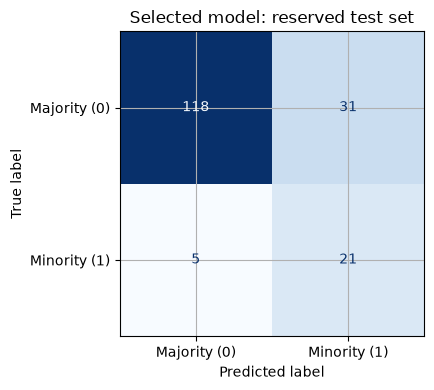

In [10]:
best_model = search.best_estimator_
y_pred = best_model.predict(X_test)
prob = best_model.predict_proba(X_test)
classes = best_model.named_steps["logistic"].classes_
positive_column = int(np.flatnonzero(classes == 1)[0])
display(pd.DataFrame([{
    "accuracy": accuracy_score(y_test, y_pred),
    "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
    "minority_precision": precision_score(y_test, y_pred, zero_division=0),
    "minority_recall": recall_score(y_test, y_pred),
    "minority_f1": f1_score(y_test, y_pred),
    "ROC_AUC": roc_auc_score(y_test, prob[:, positive_column]),
    "log_loss": log_loss(y_test, prob, labels=classes)}]))
print(classification_report(y_test, y_pred, digits=3, zero_division=0))
assert np.allclose(prob.sum(axis=1), 1.0)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
    display_labels=["Majority (0)", "Minority (1)"], cmap="Blues", colorbar=False)
plt.title("Selected model: reserved test set")
plt.tight_layout()
plt.show()

## 12. Multinomial logistic regression

For K mutually exclusive classes,

$$p_k(\mathbf{x})=\frac{e^{\mathbf{w}_k^\top\mathbf{x}+b_k}}
{\sum_je^{\mathbf{w}_j^\top\mathbf{x}+b_j}}.$$

The core settings have the same purposes: C controls shrinkage; l1_ratio controls penalty mixture; class_weight controls class loss contributions; solver/tol/max_iter control fitting. Choose a multinomial-compatible solver.

This separate Iris experiment selects C by negative log loss and evaluates on its own held-out partition. lbfgs handles the L2 multinomial objective; no multi_class argument is needed. Independently trained sigmoid classifiers are a different one-vs-rest approach.

In [11]:
Xi, yi = load_iris(return_X_y=True)
Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    Xi, yi, test_size=0.25, random_state=42, stratify=yi)
iris_search = GridSearchCV(make_pipeline_model(),
    {"logistic__C": [0.1, 1.0, 10.0]},
    cv=StratifiedKFold(3, shuffle=True, random_state=42),
    scoring="neg_log_loss", refit=True, n_jobs=1, error_score="raise")
iris_search.fit(Xi_train, yi_train)
iris_prob = iris_search.predict_proba(Xi_test)
print("Selected C:", iris_search.best_params_["logistic__C"])
print("Test accuracy:", accuracy_score(yi_test, iris_search.predict(Xi_test)))
print("Test log loss:", log_loss(yi_test, iris_prob))
print("Probability columns:", iris_search.classes_)
display(pd.DataFrame(iris_prob[:5], columns=load_iris().target_names))
assert np.allclose(iris_prob.sum(axis=1), 1.0)

Selected C: 10.0
Test accuracy: 0.9473684210526315
Test log loss: 0.11010553653652656
Probability columns: [0 1 2]


,setosa,versicolor,virginica
0,0.998545,0.001455,9.319585e-14
1,0.005916,0.892403,1.016814e-01
2,0.007830,0.987067,5.102465e-03
3,0.000905,0.987530,1.156426e-02
4,0.995442,0.004558,4.619656e-13


## 13. Decision guide and practice

| Need | Starting action | Reason |
|---|---|---|
| Baseline | Scale + L2 + lbfgs + C=1 | Straightforward compatible starting point |
| Noisy, sensitive coefficients | Validate smaller C | Stronger shrinkage |
| Sparse model | SAGA + L1; tune C | L1 can set coefficients to zero |
| Sparsity and smoother shrinkage | SAGA + Elastic-Net | Mix L1 and L2 |
| Minority class matters | Compare weights; inspect precision and recall | Accuracy may hide minority errors |
| Convergence warning | Check scaling, then budget/tolerance | Improve optimization reliability |
| Many features, few binary examples | Benchmark liblinear L2 dual=True | May suit wide data |
| Repeated manual nearby fits | Consider warm_start | Reuse initialization |
| Parallel search | Configure GridSearchCV n_jobs | Parallelize independent fits |

**Tune modeling choices:** regularization and relevant class costs. **Configure optimization:** compatible solver, adequate iterations, sensible tolerance. **Fix repeatability:** seeds and splits.

### Frequently asked questions

**Is C a learning rate?** No; inverse regularization strength.

**Does increasing max_iter cause overfitting?** It mainly permits convergence to the same objective. Regularization directly controls coefficient penalties.

**Is L1 always better?** No. Sparsity can be useful, but correlated-feature selection can be unstable.

**Always use balanced weights?** Compare them with equal weights using relevant metrics. Recall gains may cost precision.

**Fit a scaler before CV?** Keep it inside the Pipeline to avoid leakage.

**Is temperature a classifier hyperparameter here?** Not a LogisticRegression constructor setting. It is a separate calibration choice.

### Exercises

1. Repeat the C validation curve using ROC AUC and explain why its preferred C may differ.
2. Change C in the penalty experiment and track approximately zero coefficients.
3. Compare custom class weights on development data; inspect precision and recall together.
4. Compare tol values with an adequate iteration budget; report iterations and CV score.
5. Reserve fresh evaluation data before a new tuning study. Do not optimize settings against this notebook's final test results.

## Reading the saved experiment results

The saved run used **scikit-learn 1.9.1**. These observations describe this run; rerunning with different data or versions can change the numbers.

- **Sparsity:** At C=0.1, L2 had 0 approximately zero coefficients, Elastic-Net had 9, and L1 had 14 out of 20. This illustrates the role of penalty type in creating a sparse model.
- **Class weighting:** At C=1, balanced weighting increased mean CV minority recall from 0.375 to 0.738 while reducing precision from 0.624 to 0.397. This is a tradeoff to assess against your task's costs.
- **Convergence:** The one-iteration fit raised a convergence warning. With a budget of 2000, the solver stopped after 9 iterations without that warning; it did not use the entire budget. Training log loss fell from 0.420 to 0.273.
- **Search:** The 24-candidate, five-fold search selected L2 with lbfgs, C=0.1, and balanced class weights. Mean CV balanced accuracy was 0.776. C=0.1 was selected jointly with class weights; it need not match the preferred C in the earlier equal-weight validation curve.
- **Final binary evaluation:** Balanced accuracy was approximately 0.800; minority recall was 0.808 and precision was 0.404. The confusion matrix shows why considering both recall and false positives matters.

These results illustrate the controls, not universal recommendations. All 11 code cells executed successfully; the intentional convergence warning was captured and reported locally. The legacy syntax branch is included for compatibility, but was not executed in this saved run.

## 14. Official scikit-learn references

**Consulted directly for this notebook**

1. [LogisticRegression API](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html): defaults, meanings, compatibility, version changes.
2. [GridSearchCV API](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html): grids, scoring, refit, CV, parallelism, results.

**Related official documentation**

3. [Logistic regression user guide](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression): objectives and multinomial behavior; consulted earlier for the accompanying softmax guide.
4. [Tuning hyperparameters](https://scikit-learn.org/stable/modules/grid_search.html): search strategies and selection.
5. [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html): chained preprocessing and models.
6. [Data leakage pitfalls](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage): preprocessing inside training folds.
7. [LogisticRegressionCV](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegressionCV.html): built-in regularization CV.
8. [Decision threshold tuning](https://scikit-learn.org/stable/modules/classification_threshold.html): probability estimates versus decisions.
9. [L1 and L2 sparsity example](https://scikit-learn.org/stable/auto_examples/linear_model/plot_logistic_l1_l2_sparsity.html): comparison of penalties.

Stable URLs can change with new releases. Check documentation matching your installed version when adapting code. The compatibility branch for older versions is provided for convenience; saved execution identifies the version actually tested.

Local notes: [Softmax derivations](Multinomial_Logistic_Regression_Softmax_Regression.md) and [temperature](README.md).